# 1. Download Landsat imagery

In this notebook I search the Microsoft Planetary Computer for cloud-free Landsat surface reflectance imagery covering the April 2026 wildfire in Powys, Wales, and save each scene as a GeoTIFF to the `data/multispectral` directory.

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import odc.stac
import pandas as pd
import planetary_computer
import pystac_client
import rioxarray  # noqa: F401 - registers the `.rio` accessor used to save GeoTIFFs
from pystac import ItemCollection
from shapely import box

## File paths

All paths are relative to this notebook (which sits in `notebooks/`).

In [2]:
data_dir = Path("..") / "data"
multispectral_dir = data_dir / "multispectral"
fire_outline_fpath = data_dir / "effis_modis_powys_20260427.gpkg"

# Create the multispectral directory if it doesn't exist
multispectral_dir.mkdir(parents=True, exist_ok=True)

## Search parameters

In [4]:
aoi_name = "powys"

# Bounding box as [min_lon, min_lat, max_lon, max_lat] (EPSG:4326)
bbox = [-3.80182451, 52.23087296, -3.58495919, 52.38308418]

# Date range in the format "YYYY-MM-DD/YYYY-MM-DD"
daterange = "2026-04-20/2026-05-31"

# Maximum scene cloud cover (%)
max_cloud_percent = 20

# Minimum fraction of the AOI that a scene must cover
aoi_fraction_threshold = 0.7

# Planetary Computer collection: Landsat Collection 2 Level-2 (surface reflectance)
collection = "landsat-c2-l2"

Sanity check that bounding box covers fire vector:

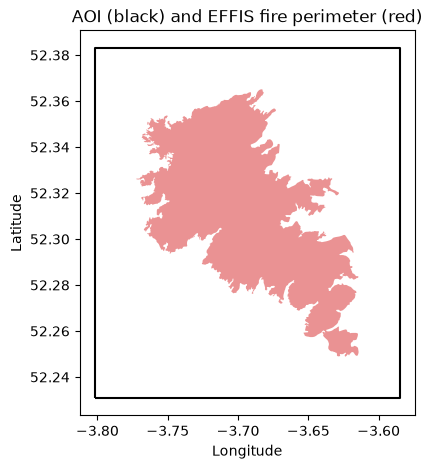

In [8]:
aoi_gdf = gpd.GeoDataFrame(geometry=[box(*bbox)], crs="EPSG:4326")
fire_gdf = gpd.read_file(fire_outline_fpath).to_crs("EPSG:4326")

fig, ax = plt.subplots(figsize=(5, 5))
aoi_gdf.boundary.plot(ax=ax, color="k", label="AOI")
fire_gdf.plot(ax=ax, color="tab:red", alpha=0.5)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("AOI (black) and EFFIS fire perimeter (red)")
plt.show()

## Search the Planetary Computer catalogue

In [5]:
catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace,  # signs asset URLs so they can be downloaded
)

search = catalog.search(
    collections=[collection],
    bbox=bbox,
    datetime=daterange,
    query={
        "eo:cloud_cover": {"lt": max_cloud_percent},
        "platform": {"in": ["landsat-8", "landsat-9"]},
    },
)

items = search.item_collection()
print(f"Found {len(items)} matching scene(s).")

Found 5 matching scene(s).


## Load the imagery

On 29 April, the AOI was imaged by two neighbouring scenes (WRS rows 023 and 024) from the same Landsat 9 overpass. Setting `groupby="solar_day"` merges scenes acquired on the same day into a single mosaic, so I end up with one image per date.

In [10]:
bands = ["blue", "green", "red", "nir08", "swir16", "swir22"]

ds = odc.stac.load(
    items,
    bands=bands,
    bbox=bbox,
    groupby="solar_day",
    with_properties=[
        {"key": "platform", "dtype": "str"},
        {"key": "landsat:scene_id", "dtype": "str"},
    ],
)

# Store the platform and scene ID as coordinates rather than data variables
ds = ds.set_coords(["platform", "landsat_scene_id"])

# Load the data into memory (this is where the download happens)
ds = ds.compute()
ds

<xarray.Dataset> Size: 14MB
Dimensions:           (y: 570, x: 500, time: 4)
Coordinates:
  * y                 (y) float64 5kB 5.804e+06 5.804e+06 ... 5.787e+06
  * x                 (x) float64 4kB 4.452e+05 4.453e+05 ... 4.602e+05
  * time              (time) datetime64[ns] 32B 2026-04-22T11:04:31.047035 .....
    platform          (time) <U19 304B 'landsat-9' ... 'landsat-9'
    landsat_scene_id  (time) <U43 688B 'LC92030242026112LGN00' ... 'LC9203024...
    spatial_ref       int32 4B 32630
Data variables:
    blue              (time, y, x) uint16 2MB 7933 7942 8107 ... 9079 9098 8918
    green             (time, y, x) uint16 2MB 8604 8661 8752 ... 10561 10217
    red               (time, y, x) uint16 2MB 8374 8436 8627 ... 10813 10479
    nir08             (time, y, x) uint16 2MB 16820 16313 15547 ... 20936 20413
    swir16            (time, y, x) uint16 2MB 11425 11947 11745 ... 17799 17065
    swir22            (time, y, x) uint16 2MB 9232 9487 9780 ... 12947 12636

## Convert to surface reflectance

In [11]:
da = ds.to_array(dim="band")
da = da.where(da > 0)                  # 0 = no data
da = da * 0.0000275 - 0.2              # Collection 2 Level-2 surface reflectance scaling
da.attrs["long_name"] = list(da["band"].values)
da

<xarray.DataArray (band: 6, time: 4, y: 570, x: 500)> Size: 27MB
array([[[[0.0181575 , 0.01840501, 0.0229425 , ..., 0.0442275 ,
          0.04378749, 0.04356749],
         [0.020165  , 0.02112749, 0.0229975 , ..., 0.044475  ,
          0.0451625 , 0.04290751],
         [0.02209   , 0.0221725 , 0.0287175 , ..., 0.04274251,
          0.0399375 , 0.0421375 ],
         ...,
         [0.03111   , 0.03204499, 0.02720501, ..., 0.07285501,
          0.06240501, 0.0505525 ],
         [0.0329525 , 0.030725  , 0.0317425 , ..., 0.07359751,
          0.07169999, 0.05462249],
         [0.03600501, 0.03443749, 0.0372425 , ..., 0.06958251,
          0.06930749, 0.05643751]],

        [[0.0158475 , 0.0190925 , 0.01835001, ..., 0.03839751,
          0.03737999, 0.0371875 ],
         [0.0179375 , 0.016535  , 0.0182675 , ..., 0.039635  ,
          0.03845251, 0.0358675 ],
         [0.01895499, 0.0160125 , 0.02552749, ..., 0.0371875 ,
          0.0336675 , 0.03507   ],
...
          0.1762275 , 0.1564825 ],
         [0.096725  , 0.103985  , 0.09177499, ..., 0.1947075 ,
          0.1953675 , 0.15945251],
         [0.1017025 , 0.11622249, 0.11809249, ..., 0.19151749,
          0.1900325 , 0.17138751]],

        [[       nan,        nan,        nan, ..., 0.10283001,
          0.10074   , 0.09826501],
         [       nan,        nan,        nan, ..., 0.0994475 ,
          0.10071249, 0.09892501],
         [       nan,        nan,        nan, ..., 0.10101499,
          0.09680749, 0.10041   ],
         ...,
         [0.0907575 , 0.10230751, 0.0838825 , ..., 0.16805999,
          0.1533475 , 0.14273249],
         [0.09438749, 0.09969501, 0.09425001, ..., 0.158655  ,
          0.1629725 , 0.1417975 ],
         [0.09950249, 0.10731249, 0.10822   , ..., 0.155795  ,
          0.1560425 , 0.14749001]]]],
      shape=(6, 4, 570, 500), dtype=float32)
Coordinates:
  * band              (band) object 48B 'blue' 'green' ... 'swir16' 'swir22'
  * time              (time) datetime64[ns] 32B 2026-04-22T11:04:31.047035 .....
    platform          (time) <U19 304B 'landsat-9' ... 'landsat-9'
    landsat_scene_id  (time) <U43 688B 'LC92030242026112LGN00' ... 'LC9203024...
  * y                 (y) float64 5kB 5.804e+06 5.804e+06 ... 5.787e+06
  * x                 (x) float64 4kB 4.452e+05 4.453e+05 ... 4.602e+05
    spatial_ref       int32 4B 32630
Attributes:
    long_name:  ['blue', 'green', 'red', 'nir08', 'swir16', 'swir22']

## Quality check

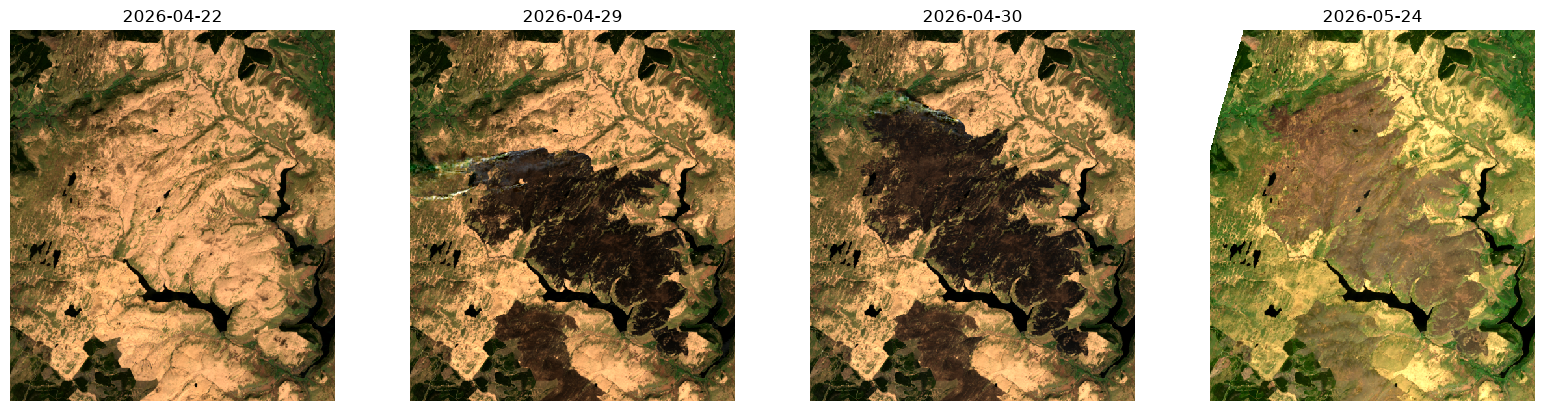

In [12]:
n_dates = da.sizes["time"]
fig, axes = plt.subplots(1, n_dates, figsize=(4 * n_dates, 4), layout="constrained")

for ax, t in zip(np.atleast_1d(axes), da["time"].values):
    da.sel(time=t, band=["red", "green", "blue"]).plot.imshow(ax=ax, robust=True)
    ax.set_title(str(t)[:10])
    ax.set_aspect("equal")
    ax.set_axis_off()

plt.show()

## Save

In [15]:
for t in da["time"].values:
    scene = da.sel(time=t)

    date = str(t)[:10]

    # Merged dates list their platforms and scene IDs separated by commas
    # (e.g. "landsat-9,landsat-9"), so I remove any duplicates
    platform = "-and-".join(sorted(set(str(scene["platform"].values).split(","))))
    scene_ids = str(scene["landsat_scene_id"].values).split(",")

    filepath = multispectral_dir / f"{aoi_name}_{date}_{platform}.tif"

    # Drop the per-scene metadata coordinates before saving
    scene = scene.drop_vars(["platform", "landsat_scene_id"])
    scene.rio.to_raster(filepath, compress="deflate", dtype="float32")
    print(f"Saved {filepath}")

Saved ../data/multispectral/powys_2026-04-22_landsat-9.tif
Saved ../data/multispectral/powys_2026-04-29_landsat-9.tif
Saved ../data/multispectral/powys_2026-04-30_landsat-8.tif
Saved ../data/multispectral/powys_2026-05-24_landsat-9.tif
